# Instal Library

In [ ]:
!pip install pandas numpy scipy bitstring pycryptodome

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 344.0/344.0 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.5/423.5 kB 10.0 MB/s eta 0:00:00


# Import Library

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
from bitstring import BitArray
import base64
import matplotlib.pyplot as plt

# Import Data

In [ ]:
file_path1 = '/content/DataEsp1Clean.csv'  # Datasheet 1
file_path2 = '/content/DataEsp2Clean.csv' # Datasheet 2

df1 = pd.read_csv(file_path1)
df2 = pd.read_csv(file_path2)

In [ ]:
# Daftar kolom yang akan dihitung byte
cols_df1 = ['Tegangan', 'Arus', 'Daya', 'Energi']
cols_df2 = ['TeganganEnkripsi', 'ArusEnkripsi', 'DayaEnkripsi', 'EnergiEnkripsi']

# Hitung Panjang Byte

In [ ]:
# Fungsi menghitung byte
def byte_count(x):
    return len(str(x).encode('utf-8'))

In [ ]:
# ----- DataEsp1Clean.csv -----
# Hitung byte per sel
for col in cols_df1:
    df1[col + '_byte'] = df1[col].apply(byte_count)

# Buat tabel rapi
byte_table_df1 = df1[[col for col in df1.columns if col in cols_df1 or '_byte' in col]]

# Tambahkan baris rata-rata
avg_row_df1 = {col: df1[col + '_byte'].mean() if col in cols_df1 else '' for col in cols_df1}
avg_row_df1.update({col + '_byte': df1[col + '_byte'].mean() for col in cols_df1})
avg_row_df1 = pd.DataFrame([avg_row_df1], index=['Rata-rata'])
byte_table_df1 = pd.concat([byte_table_df1, avg_row_df1])

print("Jumlah byte setiap data pada DataEsp1Clean.csv:")
display(byte_table_df1)

Jumlah byte setiap data pada DataEsp1Clean.csv:


,Tegangan,Arus,Daya,Energi,Tegangan_byte,Arus_byte,Daya_byte,Energi_byte
0,222.2,0.280000,33.6,0.690000,5.0,4.000000,4.0,4.000000
1,222.3,0.250000,29.5,0.700000,5.0,4.000000,4.0,3.000000
2,222.8,0.220000,24.4,0.700000,5.0,4.000000,4.0,3.000000
3,222.9,0.210000,23.7,0.710000,5.0,4.000000,4.0,4.000000
4,223.2,0.200000,22.5,0.710000,5.0,3.000000,4.0,4.000000
...,...,...,...,...,...,...,...,...
116,218.8,0.130000,14.6,0.850000,5.0,4.000000,4.0,4.000000
117,218.7,0.130000,14.2,0.860000,5.0,4.000000,4.0,4.000000
118,218.7,0.130000,14.7,0.860000,5.0,4.000000,4.0,4.000000
119,218.8,0.130000,14.4,0.860000,5.0,4.000000,4.0,4.000000


In [ ]:
# Fungsi hitung byte per sel
def byte_count(x):
    if pd.isnull(x):
        return 0
    return len(str(x).encode('utf-8'))

# Hitung byte per kolom
for col in cols_df2:
    df1[col + '_byte'] = df1[col].apply(byte_count)

# Pilih kolom asli + kolom byte
display_cols = cols_df2 + [col + '_byte' for col in cols_df2]

# Buat tabel rapi
byte_table_df2 = df1[display_cols].copy()

# Tambahkan baris rata-rata untuk kolom byte
avg_row = {col: '' for col in cols_df2}  # kosong untuk kolom asli
avg_row.update({col + '_byte': df1[col + '_byte'].mean() for col in cols_df2})
avg_row_df = pd.DataFrame([avg_row], index=['Rata-rata'])

# Gabungkan
byte_table_df2 = pd.concat([byte_table_df2, avg_row_df])

# Tampilkan
print("\nJumlah byte setiap data enkripsi pada DataEsp1Clean.csv:")
display(byte_table_df2)


Jumlah byte setiap data enkripsi pada DataEsp1Clean.csv:


,TeganganEnkripsi,ArusEnkripsi,DayaEnkripsi,EnergiEnkripsi,TeganganEnkripsi_byte,ArusEnkripsi_byte,DayaEnkripsi_byte,EnergiEnkripsi_byte
0,1RMxmsgv9y21tLvf1892YO+sqOR4HkQfMxN3SWNPJ/qK3Y...,AVqQwz74BFNjl9yu9lr3GDWhibUPZMhaRpN+gadm0+H39Y...,R7CklEg/zvBvie9etyFI4WsMkmKTUmiaY0bW1hs8Gfuy5Q...,xzgMe9AMqmTOjCn/CAtwySqqu2l/FTBBsrc1bcPyxsXEvX...,344.0,344.0,344.0,344.0
1,IKnvfhQWZX8+Shta1NFdAFrylVaPQZd4HxrCBsGdRnfnr/...,dPV797tRzIviDcUprtPYh+qSSIsFh3xAVmjfGCVTIfNIiT...,z3/GYf9+w+2IbA6/M+IQj9LQxsJUfSpw4hUh4voFLUuFqk...,s0Zkz9jdOVWH8e7xF6ZCHiRE/YLHrot0kv+859TRDEmpA+...,344.0,344.0,344.0,344.0
2,LdFlMb9LvEr8kBhPvelYdDyfn4ibcGJbHy3cg+XeMwsMf6...,yrRFTkOB2o6c+oLPexd2Wfb54VjrmYHec0MLL5iCuVaJ7x...,zw6ci/OpqkgURCgc5n+ekCUsik5KXALiGFsDr1N6bnMvB9...,kraNQzC+xIW6MTrAil0LGTHxGXzumQwhYcEORuiq6EwBwk...,344.0,344.0,344.0,344.0
3,MP7KuNGY7DtzNGgum/ZMkFUDYkGQrBWTX1EtIyIpaeRUZq...,u6Mg0zQiQ9zmGrImSl0jkhnwhQ3aTuzucfyL8mSkipAuAd...,dqjrVScBhKlh7xPbQDYUMueYQG1riJw+Tcq+zdsaQuSvcN...,nWlPxVZ0juIdebZbjrmYHNEc8EgR69Pw89NwYP1M9r7yeh...,344.0,344.0,344.0,344.0
4,XXTRgAMJ3y4NMGU9g0GSEL/ytpMMYCfiW29QreRRMbgE3r...,PFXjnVETBdPJtN0C0jVcId3N3kNbk2ipGyaciESlC9AO28...,giYRmLDGOLs5FuVdeAwg/LnF77zoDKaC21V9WlsIlxdhyo...,LYYUMvnsjiBAN42Arftj/JzZIpkOzyN9I3EJJn6L0+n9dD...,344.0,344.0,344.0,344.0
...,...,...,...,...,...,...,...,...
116,lESpRAgYNPiFnf/Ll2hx8jO58O8YHLZflFmzhJ9RFhis4p...,SB/zd7lLQC+7xcjqEZ3YR07eGcEzuXKsZ1qRfpbudHoGKp...,HWnTcpY8IDm2EZk1wqNAJ87UiuUTLCqBau0P/0r7E2w+1o...,4KPvHpDaw6DU8hZqWPwZSLxputrw12r3XBQEWyPWcNxjxK...,344.0,344.0,344.0,344.0
117,wvfGxQjyhyhH+4+3G8JP/4IoWimlgZZCaMRouwTOBo5HId...,xjFsQdqye2763NSw5AVwNkbeH16Qbsj/zxLJsjtBtwfi2q...,AjD0ZUesw1Ds0o0hJbOq9EoK2w40A7mgX7di30chiBT+WR...,dbOpqlolQhs1Bi2Hk7Rg74a0wnqg6GFdFSrHntde8/DqZc...,344.0,344.0,344.0,344.0
118,pomoYVKNcW8/MoxAfrNsYG2+JAa30tJTz0Wb1qyV2D1tzu...,3nkDgGoIj3G5VY8D+/fblXcoCZ3EnVBjzvQEDsm//zw1vm...,BCNWrSu3HJ8VZg0XAt/TCZyWOEJkQS2AZ63VKpVeNAQ47V...,YtcKW5zND/GeRWawls1aDrZ9S0JVSNA9/29Ro0u1Y+7kHs...,344.0,344.0,344.0,344.0
119,WaeRBzw0foOfu9e0lCvEKU8EAQrUKoVgadj1NsMy30UWzX...,Cnbg2z64lARItk2QJQhKK/FmtXG5CSG6p+g3YjmKBLkzdv...,XnbYuiZNGIQrJyykL4J0+VBOFfiY2n/27PLWHHmJGt9xlo...,XpeY//1uY9AmMFlDGLFc+4IhetPBBofnKv4wLvXcax1R1r...,344.0,344.0,344.0,344.0


# Pemetaan Entropy dan Avalanche

In [ ]:
encrypted_columns = ['TeganganEnkripsi', 'ArusEnkripsi', 'DayaEnkripsi', 'EnergiEnkripsi']

In [ ]:
def shannon_entropy(data_bytes):
    counts = np.bincount(np.frombuffer(data_bytes, dtype=np.uint8))
    probs = counts / counts.sum()
    return entropy(probs, base=2)

In [ ]:
def compute_avalanche_bytes(cipher_bytes1, cipher_bytes2):
    bits1 = BitArray(bytes=cipher_bytes1)
    bits2 = BitArray(bytes=cipher_bytes2)
    min_len = min(len(bits1), len(bits2))
    diff_bits = (bits1[:min_len] ^ bits2[:min_len]).count(1)
    percent_change = diff_bits / min_len * 100
    return percent_change

In [ ]:
for col in encrypted_columns:
    cipher_bytes1 = [base64.b64decode(x) for x in df1[col]]
    df1[f'{col}_Entropy'] = [shannon_entropy(cb) for cb in cipher_bytes1]

# Uji Entropy

In [ ]:
entropy_cols = [f'{col}_Entropy' for col in encrypted_columns]
print('--- Hasil Entropi ---')
print(df1[entropy_cols])

--- Hasil Entropi ---
     TeganganEnkripsi_Entropy  ArusEnkripsi_Entropy  DayaEnkripsi_Entropy  \
0                    7.161842              7.231764              7.132998   
1                    7.203463              7.149657              7.174366   
2                    7.167197              7.087547              7.241001   
3                    7.222918              7.195007              7.194617   
4                    7.239424              7.172061              7.132117   
..                        ...                   ...                   ...   
115                  7.168621              7.063820              7.220359   
116                  7.063820              7.179382              7.238543   
117                  7.221393              7.169502              7.277606   
118                  7.159384              7.199481              7.230087   
119                  7.135709              7.134032              7.246356   

     EnergiEnkripsi_Entropy  
0                  7.18

In [ ]:
entropy_stats = df1[entropy_cols].describe().T  # T = transpose supaya kolom jadi index
entropy_stats = entropy_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

# Print hasil statistik
print('--- Statistik Hasil Entropi ---')
print(entropy_stats)

--- Statistik Hasil Entropi ---
                              mean       std       min       25%       50%  \
TeganganEnkripsi_Entropy  7.173480  0.055124  7.024594  7.142319  7.170581   
ArusEnkripsi_Entropy      7.180361  0.050339  7.045536  7.147466  7.180466   
DayaEnkripsi_Entropy      7.170801  0.053456  7.054229  7.131083  7.171298   
EnergiEnkripsi_Entropy    7.169560  0.051212  7.028877  7.135858  7.180661   

                               75%       max  
TeganganEnkripsi_Entropy  7.212725  7.295688  
ArusEnkripsi_Entropy      7.208840  7.329497  
DayaEnkripsi_Entropy      7.211674  7.299518  
EnergiEnkripsi_Entropy    7.202264  7.292740  


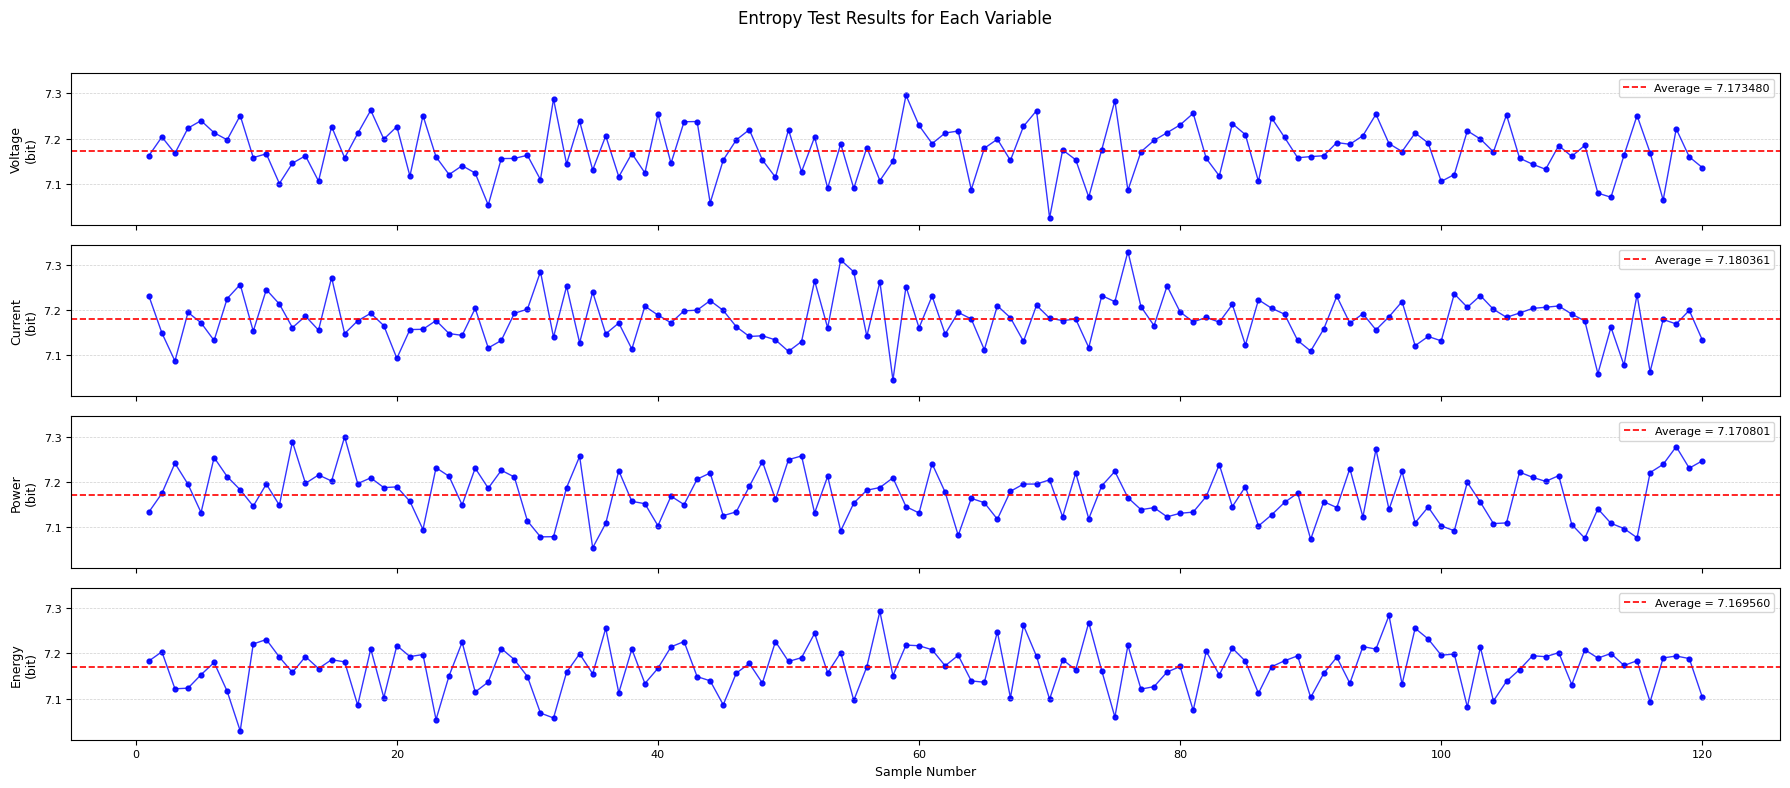

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

# Display names to keep labels short
label_map = {
    'TeganganEnkripsi': 'Voltage',
    'ArusEnkripsi': 'Current',
    'DayaEnkripsi': 'Power',
    'EnergiEnkripsi': 'Energy'
}

# Create 4 vertically stacked plots in one figure
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(18, 8),
    sharex=True,
    sharey=True
)

x = range(1, len(df1) + 1)

for ax, col in zip(axes, encrypted_columns):
    y = df1[f'{col}_Entropy']
    name = label_map.get(col, col)
    mean_value = np.mean(y)

    # Solid blue line connecting all points
    ax.plot(
        x, y,
        color='blue',
        linewidth=1.0,
        alpha=0.8
    )

    # Blue points
    ax.scatter(
        x, y,
        color='blue',
        s=12,
        alpha=0.9
    )

    # Red dashed average line
    ax.axhline(
        mean_value,
        color='red',
        linestyle='--',
        linewidth=1.2,
        label=f'Average = {mean_value:.6f}'
    )

    ax.set_ylabel(f'{name}\n(bit)', fontsize=9)
    ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.6)
    ax.legend(loc='upper right', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)

# X-axis label only on the bottom subplot
axes[-1].set_xlabel('Sample Number', fontsize=9)

# Main title
fig.suptitle('Entropy Test Results for Each Variable', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save as SVG
file_name = 'entropy_test_results_connected.svg'
plt.savefig(file_name, format='svg', bbox_inches='tight')

plt.show()

# Download automatically
files.download(file_name)

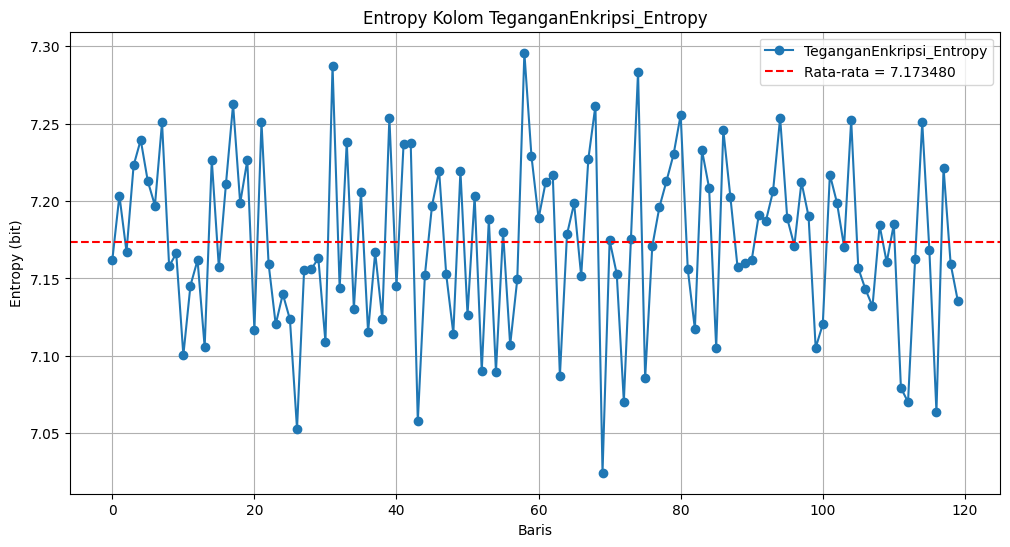

Nilai Entropy TeganganEnkripsi_Entropy: [np.float64(7.161842089725435), np.float64(7.203463269538145), np.float64(7.167196814400863), np.float64(7.222918152316842), np.float64(7.239424255790211), np.float64(7.212699706946738), np.float64(7.197074706946739), np.float64(7.250728369030761), np.float64(7.157859472504132), np.float64(7.166162976484884), np.float64(7.100476832129551), np.float64(7.145436890740203), np.float64(7.161842089725435), np.float64(7.105730652316841), np.float64(7.226510670045529), np.float64(7.157079273518899), np.float64(7.211123035095538), np.float64(7.262370751809457), np.float64(7.19859954884347), np.float64(7.226257031114783), np.float64(7.116882031114783), np.float64(7.250728369030761), np.float64(7.159384314400862), np.float64(7.120321814400862), np.float64(7.139929431622166), np.float64(7.123660693198806), np.float64(7.052958093706189), np.float64(7.155655336110304), np.float64(7.155944531114784), np.float64(7.16297683212955), np.float64(7.109069531114783), 

In [ ]:
# Nama kolom entropy
col_entropy = 'TeganganEnkripsi_Entropy'

# Ambil nilai entropy
entropy_values = df1[col_entropy].values

# Hitung rata-rata
mean_entropy = np.mean(entropy_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(entropy_values, marker='o', linestyle='-', label=f'{col_entropy}')
plt.axhline(y=mean_entropy, color='r', linestyle='--', label=f'Rata-rata = {mean_entropy:.6f}')
plt.title(f'Entropy Kolom {col_entropy}')
plt.xlabel('Baris')
plt.ylabel('Entropy (bit)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai entropy sebagai vektor
print(f"Nilai Entropy {col_entropy}:", list(entropy_values))
print(f"Rata-rata Entropy {col_entropy}: {mean_entropy:.6f}")

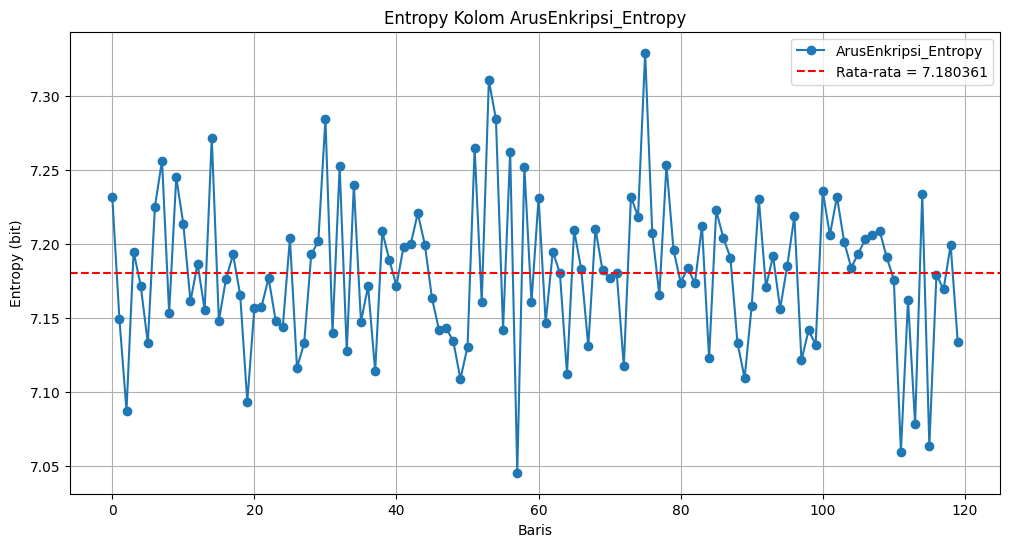

Nilai Entropy ArusEnkripsi_Entropy: [np.float64(7.23176449023282), np.float64(7.149656873011514), np.float64(7.087546972504131), np.float64(7.195007031114783), np.float64(7.172060535095538), np.float64(7.132987316491401), np.float64(7.22547683212955), np.float64(7.256625927641414), np.float64(7.15348675579021), np.float64(7.245321814400862), np.float64(7.21358081042011), np.float64(7.161299255790211), np.float64(7.186804431622166), np.float64(7.155791796672175), np.float64(7.272098193198804), np.float64(7.14823293560292), np.float64(7.176433251809459), np.float64(7.193092089725436), np.float64(7.165772876992268), np.float64(7.093545435602919), np.float64(7.157079273518899), np.float64(7.1577230119422595), np.float64(7.177076990232819), np.float64(7.14823293560292), np.float64(7.144250318381616), np.float64(7.2039542735188995), np.float64(7.116491931622168), np.float64(7.132998035095536), np.float64(7.193092089725436), np.float64(7.202039332129549), np.float64(7.284927148336087), np.flo

In [ ]:
# Nama kolom entropy untuk Arus
col_entropy = 'ArusEnkripsi_Entropy'

# Ambil nilai entropy
entropy_values = df1[col_entropy].values

# Hitung rata-rata
mean_entropy = np.mean(entropy_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(entropy_values, marker='o', linestyle='-', label=f'{col_entropy}')
plt.axhline(y=mean_entropy, color='r', linestyle='--', label=f'Rata-rata = {mean_entropy:.6f}')
plt.title(f'Entropy Kolom {col_entropy}')
plt.xlabel('Baris')
plt.ylabel('Entropy (bit)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai entropy sebagai vektor
print(f"Nilai Entropy {col_entropy}:", list(entropy_values))
print(f"Rata-rata Entropy {col_entropy}: {mean_entropy:.6f}")

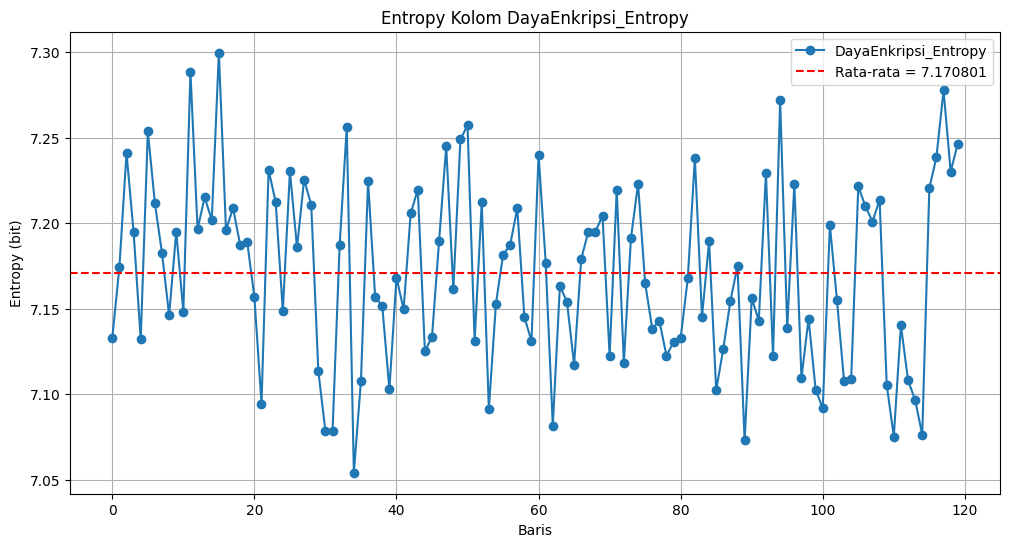

Nilai Entropy DayaEnkripsi_Entropy: [np.float64(7.132998035095536), np.float64(7.174365575977501), np.float64(7.241000927641414), np.float64(7.194616931622167), np.float64(7.132116931622167), np.float64(7.253677148336088), np.float64(7.211513134588154), np.float64(7.18233081042011), np.float64(7.146217089725435), np.float64(7.195007031114783), np.float64(7.14823293560292), np.float64(7.288366931622167), np.float64(7.196531873011515), np.float64(7.215105652316842), np.float64(7.201785693198805), np.float64(7.29951831042011), np.float64(7.19604086903076), np.float64(7.208717089725435), np.float64(7.187194531114784), np.float64(7.188719373011514), np.float64(7.156825634588151), np.float64(7.094579273518898), np.float64(7.231120751809457), np.float64(7.212156873011515), np.float64(7.148775769538144), np.float64(7.230239648336088), np.float64(7.185770593706189), np.float64(7.225375927641414), np.float64(7.210632031114783), np.float64(7.113543152316841), np.float64(7.078310535095538), np.flo

In [ ]:
# Nama kolom entropy untuk Daya
col_entropy = 'DayaEnkripsi_Entropy'

# Ambil nilai entropy
entropy_values = df1[col_entropy].values

# Hitung rata-rata
mean_entropy = np.mean(entropy_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(entropy_values, marker='o', linestyle='-', label=f'{col_entropy}')
plt.axhline(y=mean_entropy, color='r', linestyle='--', label=f'Rata-rata = {mean_entropy:.6f}')
plt.title(f'Entropy Kolom {col_entropy}')
plt.xlabel('Baris')
plt.ylabel('Entropy (bit)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai entropy sebagai vektor
print(f"Nilai Entropy {col_entropy}:", list(entropy_values))
print(f"Rata-rata Entropy {col_entropy}: {mean_entropy:.6f}")

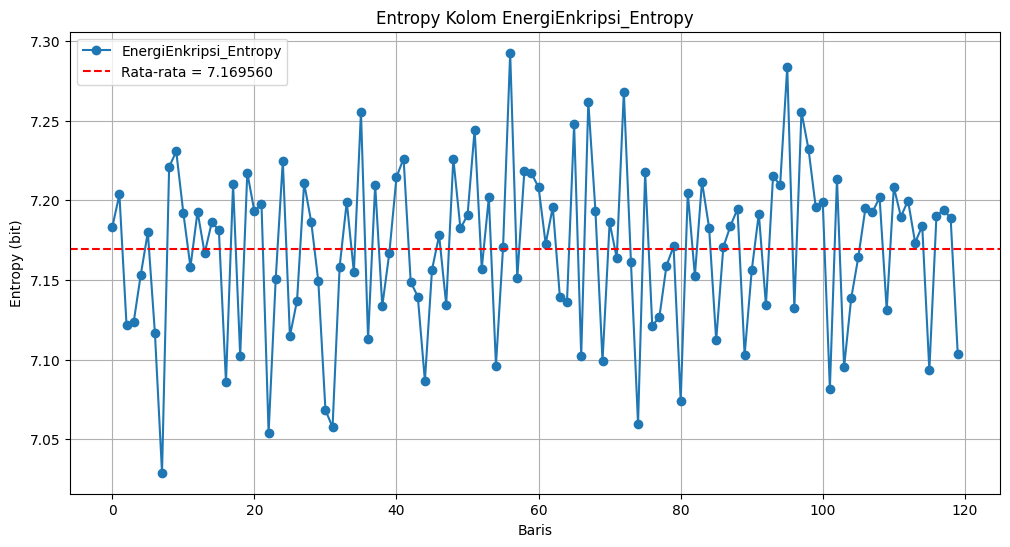

Nilai Entropy EnergiEnkripsi_Entropy: [np.float64(7.183211913893479), np.float64(7.203700634588153), np.float64(7.121846656297595), np.float64(7.123270593706189), np.float64(7.152995751809458), np.float64(7.180025769538145), np.float64(7.116491931622165), np.float64(7.028876855282827), np.float64(7.221003210927494), np.float64(7.230730652316841), np.float64(7.192058251809457), np.float64(7.1581131114348775), np.float64(7.192939355282827), np.float64(7.166705810420108), np.float64(7.186160693198806), np.float64(7.181296972504131), np.float64(7.085632031114783), np.float64(7.210241931622167), np.float64(7.102391773518899), np.float64(7.217410693198805), np.float64(7.193092089725435), np.float64(7.197565710927493), np.float64(7.053839197179558), np.float64(7.150537976484884), np.float64(7.224833093706188), np.float64(7.114814355282828), np.float64(7.136827917874234), np.float64(7.210885670045529), np.float64(7.186414332129549), np.float64(7.149013134588153), np.float64(7.068293898701708),

In [ ]:
# Nama kolom entropy untuk Energi
col_entropy = 'EnergiEnkripsi_Entropy'

# Ambil nilai entropy
entropy_values = df1[col_entropy].values

# Hitung rata-rata
mean_entropy = np.mean(entropy_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(entropy_values, marker='o', linestyle='-', label=f'{col_entropy}')
plt.axhline(y=mean_entropy, color='r', linestyle='--', label=f'Rata-rata = {mean_entropy:.6f}')
plt.title(f'Entropy Kolom {col_entropy}')
plt.xlabel('Baris')
plt.ylabel('Entropy (bit)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai entropy sebagai vektor
print(f"Nilai Entropy {col_entropy}:", list(entropy_values))
print(f"Rata-rata Entropy {col_entropy}: {mean_entropy:.6f}")

# Uji Avalanche

In [ ]:
for col in encrypted_columns:
    cipher_bytes1 = [base64.b64decode(x) for x in df1[col]]
    cipher_bytes2 = [base64.b64decode(x) for x in df2[col]]
    df1[f'{col}_Avalanche'] = [compute_avalanche_bytes(cb1, cb2)
                                for cb1, cb2 in zip(cipher_bytes1, cipher_bytes2)]

In [ ]:
# Define avalanche_cols based on encrypted_columns
avalanche_cols = [f'{col}_Avalanche' for col in encrypted_columns]

# Ambil 10 baris pertama dan 10 baris terakhir
top_10 = df1[avalanche_cols].head(10)
bottom_10 = df1[avalanche_cols].tail(10)

# Gabungkan 10 pertama + 10 terakhir
top_bottom = pd.concat([top_10, bottom_10])

# Hitung rata-rata seluruh dataset untuk setiap kolom
global_avg = pd.DataFrame(df1[avalanche_cols].mean()).T
global_avg.index = ['Rata-rata Seluruh Data']

# Gabungkan rata-rata global di bawah tabel top_bottom
avalanche_table = pd.concat([top_bottom, global_avg])

# Tampilkan tabel
print('--- Hasil Avalanche Effect (10 pertama & 10 terakhir + Rata-rata Seluruh Data) ---')
display(avalanche_table)

--- Hasil Avalanche Effect (10 pertama & 10 terakhir + Rata-rata Seluruh Data) ---


,TeganganEnkripsi_Avalanche,ArusEnkripsi_Avalanche,DayaEnkripsi_Avalanche,EnergiEnkripsi_Avalanche
0,48.291016,49.316406,50.146484,49.218750
1,48.437500,50.830078,50.292969,47.705078
2,49.511719,51.953125,51.660156,50.097656
3,50.244141,53.125000,51.171875,48.046875
4,49.951172,49.658203,50.830078,50.878906
5,49.267578,49.951172,49.169922,50.292969
6,49.023438,49.169922,50.195312,50.976562
7,51.367188,48.925781,51.806641,50.634766
8,50.390625,48.828125,51.513672,49.462891
9,49.560547,50.390625,49.853516,50.341797


In [ ]:
avalanche_data = df1[avalanche_cols]

# Statistik deskriptif lengkap
avalanche_stats = avalanche_data.describe(percentiles=[0.25, 0.5, 0.75]).T  # transpose supaya kolom jadi baris

# Tambahkan kolom Range (maks - min)
avalanche_stats['Range'] = avalanche_stats['max'] - avalanche_stats['min']

# Tampilkan hasil statistik
print('--- Statistik Avalanche Effect ---')
display(avalanche_stats)

--- Statistik Avalanche Effect ---


,count,mean,std,min,25%,50%,75%,max,Range
TeganganEnkripsi_Avalanche,120.0,49.990234,1.067532,47.265625,49.218750,50.097656,50.598145,52.441406,5.175781
ArusEnkripsi_Avalanche,120.0,49.952393,1.030807,46.484375,49.267578,49.902344,50.683594,53.125000,6.640625
DayaEnkripsi_Avalanche,120.0,50.100505,1.138581,46.630859,49.523926,50.146484,50.842285,52.929688,6.298828
EnergiEnkripsi_Avalanche,120.0,49.930420,1.076113,47.216797,49.218750,49.926758,50.646973,53.271484,6.054688


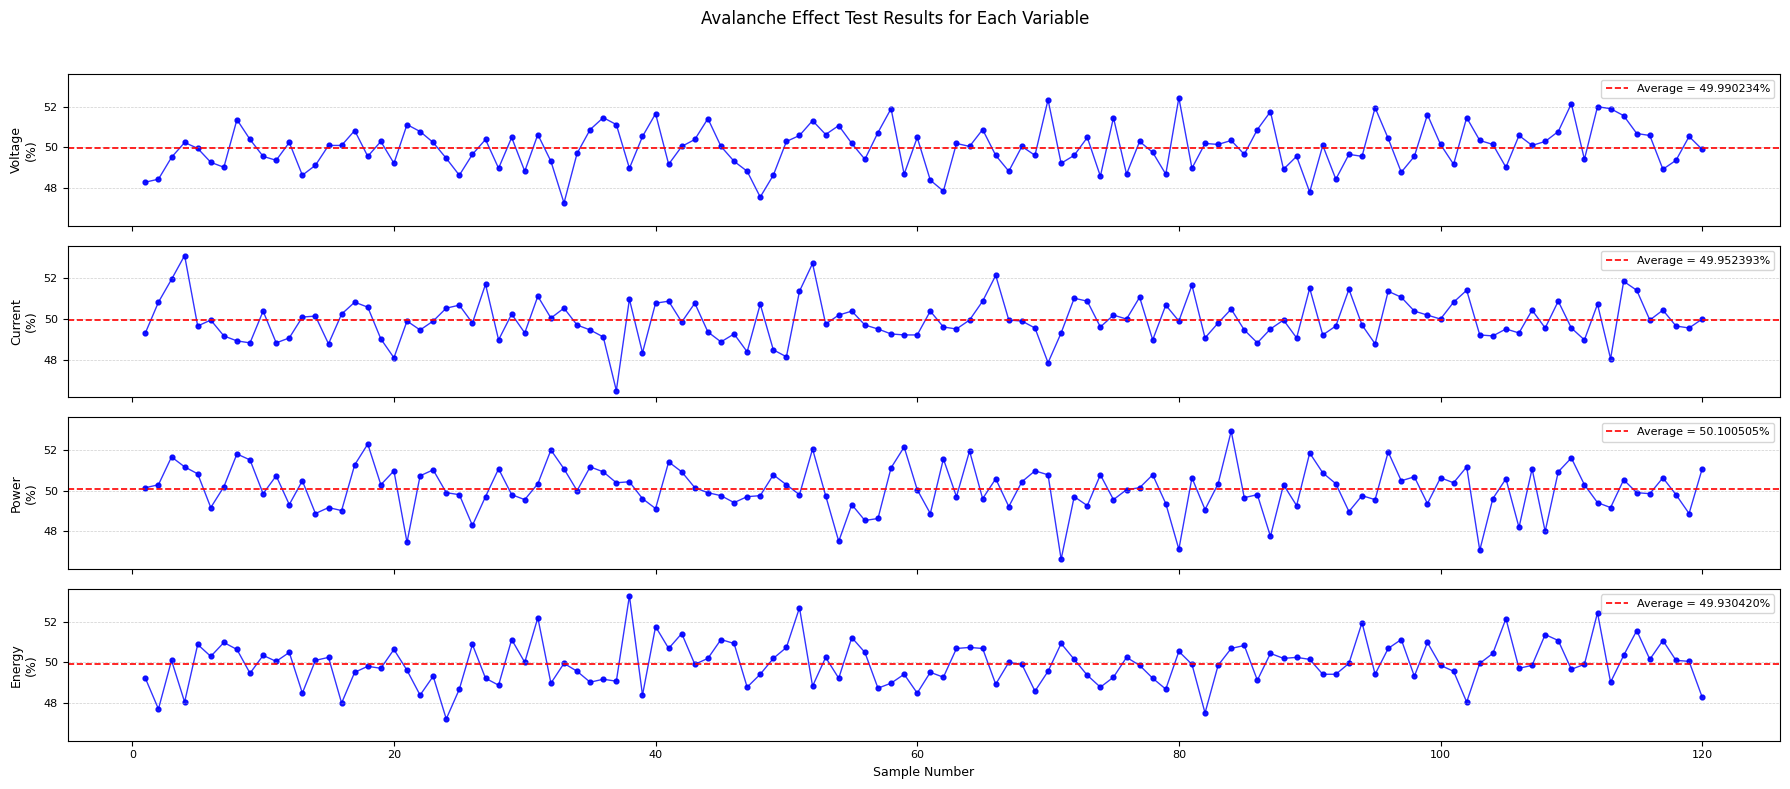

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

# Display names to keep labels short
label_map = {
    'TeganganEnkripsi': 'Voltage',
    'ArusEnkripsi': 'Current',
    'DayaEnkripsi': 'Power',
    'EnergiEnkripsi': 'Energy'
}

# Create 4 vertically stacked plots in one figure
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(18, 8),
    sharex=True,
    sharey=True
)

x = range(1, len(df1) + 1)

for ax, col in zip(axes, encrypted_columns):
    y = df1[f'{col}_Avalanche']
    name = label_map.get(col, col)
    mean_value = np.mean(y)

    # Solid blue line connecting all points
    ax.plot(
        x, y,
        color='blue',
        linewidth=1.0,
        alpha=0.8
    )

    # Blue points
    ax.scatter(
        x, y,
        color='blue',
        s=12,
        alpha=0.9
    )

    # Red dashed average line
    ax.axhline(
        mean_value,
        color='red',
        linestyle='--',
        linewidth=1.2,
        label=f'Average = {mean_value:.6f}%'
    )

    ax.set_ylabel(f'{name}\n(%)', fontsize=9)
    ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.6)
    ax.legend(loc='upper right', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)

# X-axis label only on the bottom subplot
axes[-1].set_xlabel('Sample Number', fontsize=9)

# Main title
fig.suptitle('Avalanche Effect Test Results for Each Variable', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save as SVG
file_name = 'avalanche_effect_test_results_connected.svg'
plt.savefig(file_name, format='svg', bbox_inches='tight')

plt.show()

# Download automatically
files.download(file_name)

In [ ]:
print(df1.dtypes)

In [ ]:
# Nama kolom Avalanche
col_avalanche = 'TeganganEnkripsi_Avalanche'

# Ambil nilai Avalanche
avalanche_values = df1[col_avalanche].values

# Hitung rata-rata
mean_avalanche = np.mean(avalanche_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(avalanche_values, marker='o', linestyle='-', color='red', label=f'{col_avalanche}')
plt.axhline(y=mean_avalanche, color='green', linestyle='--', label=f'Rata-rata = {mean_avalanche:.6f}')
plt.title(f'Avalanche Effect Kolom {col_avalanche}')
plt.xlabel('Baris')
plt.ylabel('Persentase Bit Berubah (%)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai Avalanche sebagai vektor
print(f"Nilai Avalanche {col_avalanche}:", list(avalanche_values))
print(f"Rata-rata Avalanche {col_avalanche}: {mean_avalanche:.6f}")

In [ ]:
# Nama kolom Avalanche
col_avalanche = 'ArusEnkripsi_Avalanche'

# Ambil nilai Avalanche
avalanche_values = df1[col_avalanche].values

# Hitung rata-rata
mean_avalanche = np.mean(avalanche_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(avalanche_values, marker='o', linestyle='-', color='red', label=f'{col_avalanche}')
plt.axhline(y=mean_avalanche, color='green', linestyle='--', label=f'Rata-rata = {mean_avalanche:.6f}')
plt.title(f'Avalanche Effect Kolom {col_avalanche}')
plt.xlabel('Baris')
plt.ylabel('Persentase Bit Berubah (%)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai Avalanche sebagai vektor
print(f"Nilai Avalanche {col_avalanche}:", list(avalanche_values))
print(f"Rata-rata Avalanche {col_avalanche}: {mean_avalanche:.6f}")

In [ ]:
# Nama kolom Avalanche
col_avalanche = 'DayaEnkripsi_Avalanche'

# Ambil nilai Avalanche
avalanche_values = df1[col_avalanche].values

# Hitung rata-rata
mean_avalanche = np.mean(avalanche_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(avalanche_values, marker='o', linestyle='-', color='red', label=f'{col_avalanche}')
plt.axhline(y=mean_avalanche, color='green', linestyle='--', label=f'Rata-rata = {mean_avalanche:.6f}')
plt.title(f'Avalanche Effect Kolom {col_avalanche}')
plt.xlabel('Baris')
plt.ylabel('Persentase Bit Berubah (%)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai Avalanche sebagai vektor
print(f"Nilai Avalanche {col_avalanche}:", list(avalanche_values))
print(f"Rata-rata Avalanche {col_avalanche}: {mean_avalanche:.6f}")

In [ ]:
# Nama kolom Avalanche
col_avalanche = 'EnergiEnkripsi_Avalanche'

# Ambil nilai Avalanche
avalanche_values = df1[col_avalanche].values

# Hitung rata-rata
mean_avalanche = np.mean(avalanche_values)

# Plot
plt.figure(figsize=(12,6))
plt.plot(avalanche_values, marker='o', linestyle='-', color='red', label=f'{col_avalanche}')
plt.axhline(y=mean_avalanche, color='green', linestyle='--', label=f'Rata-rata = {mean_avalanche:.6f}')
plt.title(f'Avalanche Effect Kolom {col_avalanche}')
plt.xlabel('Baris')
plt.ylabel('Persentase Bit Berubah (%)')
plt.legend()
plt.grid(True)
plt.show()

# Print nilai Avalanche sebagai vektor
print(f"Nilai Avalanche {col_avalanche}:", list(avalanche_values))
print(f"Rata-rata Avalanche {col_avalanche}: {mean_avalanche:.6f}")

# **PENGUJIAN WAKTU**

In [ ]:
file_waktu = '/content/DataWaktuKomputasi.csv'  # Datasheet 1
df = pd.read_csv(file_waktu)

In [ ]:
# Data hasil pengujian waktu komputasi
data_pengujian = df[
    ['waktu_dekrip', 'waktu_enkrip', 'Total']
]

print("Data Waktu Komputasi")
display(data_pengujian)

Data Waktu Komputasi


,waktu_dekrip,waktu_enkrip,Total
0,6.590,114.679,121.269
1,7.589,114.169,121.758
2,4.530,114.337,118.867
3,10.496,114.193,124.689
4,8.389,114.544,122.933
...,...,...,...
115,7.903,114.397,122.300
116,10.532,114.601,125.133
117,7.928,114.209,122.137
118,5.648,114.499,120.147


In [ ]:
# Mengubah kolom menjadi data numerik
kolom_data = ['waktu_enkrip', 'waktu_dekrip', 'Total']

for kolom in kolom_data:
    df[kolom] = pd.to_numeric(df[kolom], errors='coerce')

# ============================================================
# 2. Menampilkan tabel data
# ============================================================

data_waktu = df[
    ['waktu_enkrip', 'waktu_dekrip', 'Total']
].copy()

data_waktu.index = range(1, len(data_waktu) + 1)
data_waktu.index.name = 'Sampel'

print("Tabel Data Waktu Komputasi")
display(data_waktu)

# ============================================================
# 3. Menghitung nilai rata-rata
# ============================================================

rata_enkripsi = df['waktu_enkrip'].mean()
rata_dekripsi = df['waktu_dekrip'].mean()
rata_total = df['Total'].mean()

print(f"Rata-rata waktu enkripsi : {rata_enkripsi:.3f} ms")
print(f"Rata-rata waktu dekripsi : {rata_dekripsi:.3f} ms")
print(f"Rata-rata total waktu    : {rata_total:.3f} ms")


Tabel Data Waktu Komputasi


,waktu_enkrip,waktu_dekrip,Total
Sampel,,,
1,114.679,6.590,121.269
2,114.169,7.589,121.758
3,114.337,4.530,118.867
4,114.193,10.496,124.689
5,114.544,8.389,122.933
...,...,...,...
116,114.397,7.903,122.300
117,114.601,10.532,125.133
118,114.209,7.928,122.137


Rata-rata waktu enkripsi : 114.322 ms
Rata-rata waktu dekripsi : 7.893 ms
Rata-rata total waktu    : 122.216 ms


In [ ]:
# ============================================================
# Simpan dan download grafik secara otomatis
# ============================================================

from google.colab import files
import os

nama_output_svg = "/content/grafik_waktu_komputasi.svg"

# Simpan menggunakan objek figure
fig.savefig(
    nama_output_svg,
    format="svg",
    bbox_inches="tight"
)

# Tampilkan grafik di Google Colab
plt.show()

# Pastikan file berhasil dibuat, kemudian langsung download
if os.path.exists(nama_output_svg):
    print("Grafik berhasil disimpan. Proses download dimulai...")
    files.download(nama_output_svg)
else:
    print("File SVG gagal dibuat.")

Grafik berhasil disimpan. Proses download dimulai...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>